<a href="https://colab.research.google.com/github/PercyTechX/del-excel-al-ml/blob/main/temporada-2/02-cuando-el-arbol-se-aprende-todo/clase.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir en Colab"/></a>

# Episodio 2.2 · Cuando el árbol se aprende todo

**Serie:** Del Excel al Machine Learning · **Temporada 2** · 🎬 Video próximamente

## 🎯 Qué vas a aprender

- Una medida para cuando **no puedes vigilarlo todo**.
- Qué pasa si un árbol crece sin límite: **sobreajuste**.
- Elegir su tamaño con un **grupo de validación**, sin tocar la prueba.

## 📊 En Excel lo harías así

Imagina un `=SI()` (`IF`) con una excepción para cada despacho del año pasado. Acertaría el 100 % de ese año. Y en enero no serviría de nada, porque enero trae casos nuevos.

Es lo que vimos en el 1.6. Hoy lo vemos con árboles, donde pasa con muchísima facilidad.

## 🐍 En Python

### Paso 1: el 91 % que no dice nada

Usamos los despachos del 2.1, ahora en tres grupos: pronto verás por qué. Diciendo *"todos llegan a tiempo"* se acierta casi siempre, como en el 1.8. Por eso la exactitud no sirve aquí.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

DATOS = "https://raw.githubusercontent.com/PercyTechX/del-excel-al-ml/main/datos/"

In [2]:
def preparar_despachos(despachos):
    """Deja los datos que se conocen al preparar un despacho: textos como 0 y 1, mes y día."""
    fecha = pd.to_datetime(despachos["fecha"])
    x = pd.get_dummies(despachos[["ciudad", "tipo", "transportista"]], dtype=int)
    x = x.drop(columns=["ciudad_Lima", "tipo_Bodega", "transportista_Propio"], errors="ignore")
    x["mes"] = fecha.dt.month
    x["dia"] = fecha.dt.dayofweek
    return x.join(despachos[["distancia_km", "lineas", "presentaciones"]])

In [3]:
def parte_encontrada(periodo, real, probabilidad, vigilar=0.10):
    """Parte de los casos reales hallada al vigilar, en cada periodo, a los de mayor riesgo."""
    orden = pd.DataFrame({"periodo": periodo, "real": real, "probabilidad": probabilidad})
    orden["azar"] = np.random.default_rng(0).random(len(orden))
    orden = orden.sort_values(["periodo", "probabilidad", "azar"], ascending=[True, False, True])
    puesto = orden.groupby("periodo").cumcount()
    cupo = (orden.groupby("periodo")["real"].transform("size") * vigilar).round().clip(lower=1)
    return orden.loc[puesto < cupo, "real"].sum() / orden["real"].sum()

In [4]:
def encontrados(modelo, tabla):
    """Parte de los tardíos que se encuentra vigilando el 10 % de los despachos de cada día."""
    prob = modelo.predict_proba(preparar_despachos(tabla))[:, 1]
    return parte_encontrada(tabla["fecha"], tabla["llego_tarde"], prob)

In [5]:
despachos = pd.read_csv(DATOS + "despachos.csv")

entreno = despachos[despachos["fecha"] < "2025-01-01"]
validacion = despachos[despachos["fecha"].between("2025-01-01", "2025-06-30")]
prueba = despachos[despachos["fecha"] >= "2025-07-01"]

print("Filas:", len(entreno), len(validacion), len(prueba))
print("A tiempo en la prueba:", round(1 - prueba["llego_tarde"].mean(), 3))

Filas: 20482 10034 11321
A tiempo en la prueba: 0.909


### Paso 2: una medida nueva

Logística tiene gente para vigilar **10 de cada 100 despachos cada día**. Entonces la pregunta es: de todos los que llegaron tarde, ¿qué parte estaba entre los que vigilamos?

Es la exhaustividad del 1.8, con un cupo. Cada día se decide solo con los pedidos de ese día: no se mira el futuro. La función `parte_encontrada` lo calcula, y no hace falta memorizarla. Al azar, encontrarías cerca del 10 %. Y lo máximo posible es cerca del 75 %, porque hay días con más tardíos que puestos de vigilancia.

### Paso 3: un árbol sin límite

Le quitamos `max_depth` y miramos los aciertos en lo que ya vio:

In [6]:
sin_limite = DecisionTreeClassifier(random_state=0)
sin_limite.fit(preparar_despachos(entreno), entreno["llego_tarde"])

print("Hojas:", sin_limite.get_n_leaves())
aciertos = sin_limite.score(preparar_despachos(entreno), entreno["llego_tarde"])
print("Aciertos en entrenamiento:", round(aciertos, 3))
print("Encontrados en entrenamiento:", round(encontrados(sin_limite, entreno), 3))
print("Encontrados en validación:", round(encontrados(sin_limite, validacion), 3))

Hojas: 2801
Aciertos en entrenamiento: 0.998


Encontrados en entrenamiento: 0.752
Encontrados en validación: 0.223


Miles de hojas, y casi 100 % de aciertos en entrenamiento. Se aprendió las respuestas, igual que en el 1.6, y encuentra el 75 %, justo el máximo posible. Pero con datos nuevos baja a cerca del 22 %.

### Paso 4: ¿qué tamaño?

Probamos varios tamaños y comparamos. **No usamos la prueba para esto.** Si eligiéramos mirando la prueba, ya no sería una prueba: estaríamos haciendo trampa sin darnos cuenta.

Por eso separamos un tercer grupo, la **validación**: el primer semestre de 2025. Entrenar, validar para elegir, y probar una sola vez al final. Una limitación: esos meses no incluyen julio ni diciembre, así que elegimos sin ver la campaña.

In [7]:
filas = []
for profundidad in [2, 3, 4, 5, 6, 8, 10, 15]:
    arbol = DecisionTreeClassifier(max_depth=profundidad, random_state=0)
    arbol.fit(preparar_despachos(entreno), entreno["llego_tarde"])
    filas.append(
        {
            "profundidad": profundidad,
            "entrenamiento": encontrados(arbol, entreno),
            "validacion": encontrados(arbol, validacion),
        }
    )

curva = pd.DataFrame(filas).set_index("profundidad").round(3)

curva

,entrenamiento,validacion
profundidad,,
2,0.223,0.163
3,0.235,0.249
4,0.285,0.270
5,0.310,0.298
6,0.337,0.310
8,0.387,0.282
10,0.440,0.266
15,0.596,0.228


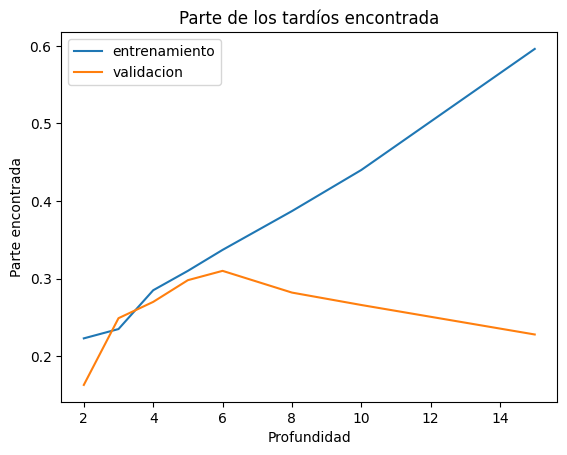

In [8]:
curva.plot(title="Parte de los tardíos encontrada", xlabel="Profundidad", ylabel="Parte encontrada")
plt.show()

Entrenamiento sube sin parar. Validación sube, llega a su punto más alto y baja. Son periodos distintos, así que en algún punto validación puede quedar arriba: lo importante es la forma. Ese punto es donde conviene detenerse: aquí, cerca de 6. Y mira que 5 queda muy cerca: **es casi un empate**, y con otros datos saldría otro número. Es una decisión, no una verdad sobre el negocio.

### Paso 5: la prueba, una sola vez

Ya elegido el tamaño, entrenamos con todo lo anterior y probamos. Comparamos con una regresión logística, usando el mes y el día como categorías, como enseñó el 1.5.

In [9]:
def con_categorias(despachos):
    """Como `preparar_despachos`, pero con el mes y el día como categorías, igual que en el 1.5."""
    x = preparar_despachos(despachos)
    for mes in range(1, 13):
        x[f"mes_{mes}"] = (x["mes"] == mes).astype(int)
    for dia in range(7):
        x[f"dia_{dia}"] = (x["dia"] == dia).astype(int)
    return x.drop(columns=["mes", "dia"])

In [10]:
previo = despachos[despachos["fecha"] < "2025-07-01"]

arbol = DecisionTreeClassifier(max_depth=6, random_state=0)
arbol.fit(preparar_despachos(previo), previo["llego_tarde"])

regresion = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
regresion.fit(con_categorias(previo), previo["llego_tarde"])
prob_regresion = regresion.predict_proba(con_categorias(prueba))[:, 1]

print("Árbol:", round(encontrados(arbol, prueba), 3))
print(
    "Regresión:", round(parte_encontrada(prueba["fecha"], prueba["llego_tarde"], prob_regresion), 3)
)

Árbol: 0.291
Regresión: 0.228


El árbol encuentra cerca del 29 % de los tardíos, de un máximo posible de cerca del 74 %, y la regresión cerca del 23 %. Gana el árbol, porque programamos reglas que actúan **en combinación**: tercero y sábado, Cusco con lluvia y lejos, y pedidos grandes en julio y diciembre. La regresión suma efectos por separado.

Eso no significa que el árbol sea mejor en general. Si le das a la regresión esas tres reglas como columnas, llega a cerca del 30 %. Lo que el árbol ahorra es tener que adivinarlas. Y en el próximo episodio verás un caso donde el árbol no aporta nada.

## 🤖 Pídeselo a la IA

> *"Explícame con un ejemplo de oficina por qué no debo elegir un modelo mirando sus resultados en los datos de prueba, y para qué sirve un grupo de validación."*

La IA te ayuda a escribir y entender código, pero **tú debes entender lo que hace**. Revisa cada respuesta antes de usarla, y no pegues datos de tu empresa.

## ✅ Resumen

| En Excel | En Python |
|---|---|
| Una regla con menos excepciones | `DecisionTreeClassifier(max_depth=6)` |
| Probar la fórmula en otro periodo | `despachos["fecha"].between(...)` |
| Cuántos casos se encuentran en el 10 % revisado | `parte_encontrada(fecha, real, probabilidad)` |
| Elegir mirando un periodo aparte | Un grupo de `validacion` |

## 📝 Ahora te toca

Abre [el ejercicio en Colab](https://colab.research.google.com/github/PercyTechX/del-excel-al-ml/blob/main/temporada-2/02-cuando-el-arbol-se-aprende-todo/ejercicio.ipynb) y busca el tamaño por tu cuenta. Cuando termines, compara con [la solución](https://colab.research.google.com/github/PercyTechX/del-excel-al-ml/blob/main/temporada-2/02-cuando-el-arbol-se-aprende-todo/solucion.ipynb).

---

*Del Excel al Machine Learning* · por [Percy Nazario](https://www.linkedin.com/in/percy-nazario/) · [Repositorio](https://github.com/PercyTechX/del-excel-al-ml) · Contenido bajo licencia CC BY 4.0